# PRACTICA 1: PROTEGIENDO LA ETSISI DE ATAQUES DE RED

## ESTUDIO CUALITATIVO

157.808 filas, 43 columnas (42 características + etiqueta). Los nombres y valores corresponden al dataset UNSW-NB15 traducido al español; la agrupación sigue cómo se construyó ese dataset.

## 1. Flujo y características básicas
Se obtienen al agrupar los paquetes capturados en flujos y contar lo que pasó en cada uno.

| Característica | Qué mide |
|---|---|
| duracion | Duración total del flujo en segundos (0 a 60 en este fichero). |
| protocolo | Protocolo de transporte o red (tcp, udp, arp, ospf…, 133 distintos). |
| servicio | Servicio de aplicación (dns, http, smtp, ftp, ssh…). Vale "-" si no se identifica. |
| estado_conexion | Estado final de la transacción: FIN (cerrada), INT (interrumpida o sin completar), CON (establecida), REQ (solo petición), RST (reseteada)… |
| paquetes_origen / paquetes_destino | Paquetes enviados en cada sentido. |
| bytes_origen / bytes_destino | Bytes transferidos en cada sentido. |
| perdidos_origen / perdidos_destino | Paquetes perdidos o retransmitidos en cada sentido. |
| ttl_origen / ttl_destino | Valor TTL de la cabecera IP en cada sentido. |
| tasa_paquetes | Paquetes por segundo del flujo. |
| carga_origen / carga_destino | Bits por segundo emitidos en cada sentido. |

## 2. Contenido (cabeceras y carga de los paquetes)

| Característica | Qué mide |
|---|---|
| ventana_origen / ventana_destino | Ventana de recepción TCP anunciada por cada extremo. |
| secuencia_origen / secuencia_destino | Número de secuencia TCP base de cada extremo. |
| tam_medio_origen / tam_medio_destino | Tamaño medio de los paquetes enviados por cada extremo, en bytes. |
| profundidad_transaccion | Profundidad de la transacción HTTP: peticiones y respuestas encadenadas en la conexión. |
| tam_respuesta | Tamaño en bytes del cuerpo de datos de la respuesta del servidor (HTTP). |

## 3. Tiempo

| Característica | Qué mide |
|---|---|
| interpaquete_origen / interpaquete_destino | Tiempo medio entre llegadas de paquetes consecutivos, en ms. |
| jitter_origen / jitter_destino | Variación de ese tiempo entre paquetes, en ms. |
| rtt_establecimiento | Tiempo de ida y vuelta del handshake TCP (= t_syn_synack + t_synack_ack). |
| t_syn_synack | Tiempo entre el SYN y el SYN-ACK. |
| t_synack_ack | Tiempo entre el SYN-ACK y el ACK final. |

## 4. Derivadas de propósito general
Se calculan después a partir de los campos anteriores; buscan firmas típicas de ataque.

| Característica | Qué mide |
|---|---|
| conex_estado_ttl | Nº de conexiones recientes con la misma combinación de estado y rango de TTL origen/destino (0 a 6). |
| flujos_metodo_http | Nº de flujos con métodos HTTP (GET, POST…). |
| comandos_ftp | Nº de flujos con comandos en sesión FTP. |
| login_ftp | Indica si la sesión FTP tiene login. Teóricamente binaria, pero toma los valores 0, 1, 2 y 4. |
| ip_puerto_iguales | 1 si IP y puerto de origen y destino coinciden (firma del ataque "land"). |

## 5. Derivadas de conexión (ventana de las últimas 100 conexiones)
Cuentan cuántas de las últimas 100 conexiones comparten rasgos con la actual.

| Característica | Conexiones con… |
|---|---|
| conex_servicio_origen | el mismo servicio y la misma IP de origen. |
| conex_servicio_destino | el mismo servicio y la misma IP de destino. |
| conex_origen | la misma IP de origen. |
| conex_destino | la misma IP de destino. |
| conex_origen_puerto_destino | la misma IP de origen y el mismo puerto de destino. |
| conex_destino_puerto_origen | la misma IP de destino y el mismo puerto de origen. |
| conex_par_origen_destino | el mismo par IP origen–destino. |

## 6. Etiqueta

| Característica | Qué mide |
|---|---|
| etiqueta | Tipo de tráfico (variable objetivo). 10 clases: Normal (50.400), Criptoanalisis (36.000), Explotacion (30.054), Fuzzing (16.366), Denegacion (11.038), Reconocimiento (9.442), Sondeo (1.800), Puerta_trasera (1.571), Inyeccion_shell (1.020), Gusano (117). |



# Agrupación de los posibles valores de la etiqueta

## Criterio de agrupación

Agrupamos haciéndonos la siguiente pregunta: **¿qué busca el atacante en ese tráfico?** Las respuestas posibles son saber, entrar, quedarse o extenderse, o dañar.

## A. Descubrimiento (antes del compromiso)
Objetivo: obtener información o encontrar debilidades, sin buscar todavía el control del sistema.

| Familia | Qué es | Huella en el fichero (9.442 / 1.800 / 16.366 filas) |
|---|---|---|
| Reconocimiento | Recogida activa de información del objetivo: escaneo de puertos y servicios, enumeración de equipos. | Mediana de 10 paquetes de origen y 0 bytes de respuesta. Reparto casi mitad TCP y mitad UDP. Servicio sin identificar en el 84 %. |
| Sondeo | Sondeo e intrusión exploratoria: escaneo de puertos, spam y pruebas contra ficheros HTML. Cercano al reconocimiento, pero más intrusivo. | Mediana de 2 paquetes y 200 bytes, sin respuesta. El 71 % de los flujos está interrumpido y el 28 % es HTTP. |
| Fuzzing | Envío de entradas aleatorias o malformadas para provocar fallos y descubrir vulnerabilidades explotables. | El 65 % es TCP. Servicio sin identificar en el 91 %. Mediana de 10 paquetes y 918 bytes de origen, con 268 bytes de respuesta. |

Fuzzing es el caso fronterizo. Su meta es descubrir vulnerabilidades, no explotarlas, y por eso va aquí. Si tiene éxito puede tumbar el servicio, pero eso es un efecto colateral, no su objetivo.

## B. Intrusión (compromiso inicial)
Objetivo: conseguir ejecución de código en el objetivo.

| Familia | Qué es | Huella en el fichero (30.054 / 1.020 filas) |
|---|---|---|
| Explotacion | Aprovechamiento de una vulnerabilidad conocida (de software, navegador o servicio) para ganar control. | El 59 % es TCP, el 26 % HTTP, el 9 % SMTP y el 5 % FTP. Mediana de 10 paquetes y 830 bytes de origen, con 354 bytes de respuesta. |
| Inyeccion_shell | Envío de *shellcode*, la carga útil que abre una consola de comandos en la víctima tras explotar el fallo. | Mediana de 2 paquetes y 542 bytes de origen, sin respuesta. El servicio nunca se identifica. Mitad TCP, mitad UDP. |

El shellcode es la carga de la explotación, así que pertenece a la misma fase.

## C. Consolidación y expansión (poscompromiso)
Objetivo: mantener el acceso conseguido o extenderlo a otros equipos.

| Familia | Qué es | Huella en el fichero (1.571 / 117 filas) |
|---|---|---|
| Puerta_trasera | Mecanismo que sortea la autenticación normal para mantener acceso persistente y remoto. | Mediana de 2 paquetes y 200 bytes. Servicio sin identificar en el 94 %. El 79 % está interrumpido y el 34 % usa protocolos distintos de TCP y UDP. |
| Gusano | Código autorreplicante que se propaga por la red. | El 88 % es HTTP sobre TCP. El 79 % de los flujos lleva método HTTP. Las peticiones son las mayores de todas las familias (mediana de 1.302 bytes). |

El gusano usa exploits para propagarse, pero lo que lo distingue de la explotación aislada es que su objetivo es expandirse a otros equipos.

## D. Ataque directo a una propiedad de seguridad (acciones sobre objetivos)
Objetivo: degradar la disponibilidad o romper la protección criptográfica.

| Familia | Qué es | Huella en el fichero (11.038 / 36.000 filas) |
|---|---|---|
| Denegacion | Denegación de servicio: agotar recursos para que el servicio deje de responder. Ataca la disponibilidad. | Mediana de 2 paquetes y 200 bytes. Servicio sin identificar en el 85 %. El 33 % usa protocolos distintos de TCP y UDP, y el 6 % es OSPF. |
| Criptoanalisis | Ataques contra primitivas criptográficas, independientes de la implementación concreta (por ejemplo, contra cifrados de bloque). Ataca la confidencialidad. | El 98 % es UDP/DNS y el 99 % de los flujos está interrumpido. Mediana de 2 paquetes y 114 bytes. Es la familia con más conexiones repetidas desde el mismo origen. |

## Totales por superfamilia

| Superfamilia | Familias | Filas | % de los ataques |
|---|---|---|---|
| A. Descubrimiento | Reconocimiento, Sondeo, Fuzzing | 27.608 | 25,7 % |
| B. Intrusión | Explotacion, Inyeccion_shell | 31.074 | 28,9 % |
| C. Consolidación y expansión | Puerta_trasera, Gusano | 1.688 | 1,6 % |
| D. Ataque directo | Denegacion, Criptoanalisis | 47.038 | 43,8 % |



## Etiquetas en el conjunto de entrenamiento/test

| Etiqueta | Train (n) | Train (%) | Test (n) | Test (%) | Dif. (pp) | Filas test / train |
|---|---|---|---|---|---|---|
| Normal | 50.400 | 31,94 | 33.300 | 44,94 | +13,00 | 0,66 |
| Criptoanalisis | 36.000 | 22,81 | 16.984 | 22,92 | +0,11 | 0,47 |
| Explotacion | 30.054 | 19,04 | 10.019 | 13,52 | −5,52 | 0,33 |
| Fuzzing | 16.366 | 10,37 | 5.456 | 7,36 | −3,01 | 0,33 |
| Denegacion | 11.038 | 6,99 | 3.680 | 4,97 | −2,02 | 0,33 |
| Reconocimiento | 9.442 | 5,98 | 3.146 | 4,25 | −1,73 | 0,33 |
| Sondeo | 1.800 | 1,14 | 609 | 0,82 | −0,32 | 0,34 |
| Puerta_trasera | 1.571 | 1,00 | 525 | 0,71 | −0,29 | 0,33 |
| Inyeccion_shell | 1.020 | 0,65 | 340 | 0,46 | −0,19 | 0,33 |
| Gusano | 117 | 0,07 | 40 | 0,05 | −0,02 | 0,34 |
| **Total** | **157.808** | **100,00** | **74.099** | **100,00** | | 0,47 |

## Resultado:
Las distribuciones de cada tipo de etiqueta no son iguales en el conjunto de entrenamiento y en el conjunto de test, aunque son razonablemente parecidas, por lo que consideramos que el modelo se comportará razonablemente bien en el mundo real y no tendrá sesgos hacia las etiquetas sobrerepresentadas en el conjunto de test. Aunque se podría mejorar haciendo que la distribución de las etiquetas en el conjunto de entrenamiento sea lo más fiel posible a la distribución en el mundo real.

# ESTUDIO CUANTITATIVO

## Estudio de escalas y proporción de ceros de las variables cuantitativas:

In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv("datos/trazas_red_entrenamiento.csv")

# Seleccionar variables cuantitativas
cuantitativas = df.select_dtypes(include="number")

# Calcular estadísticas
estudio = pd.DataFrame({
    "count": cuantitativas.count(),
    "mean": cuantitativas.mean(),
    "std": cuantitativas.std(),
    "min": cuantitativas.min(),
    "p25": cuantitativas.quantile(0.25),
    "median": cuantitativas.median(),
    "p75": cuantitativas.quantile(0.75),
    "max": cuantitativas.max(),
    "rango": cuantitativas.max() - cuantitativas.min(),
    "ceros": (cuantitativas == 0).sum(),
    "proporcion_ceros_%": (cuantitativas == 0).mean() * 100,
    "asimetria": cuantitativas.skew()
})

# Mostrar todas las filas y columnas
with pd.option_context(
    "display.max_columns", None,
    "display.max_rows", None,
    "display.width", 250
):
    display(estudio.round(4))

,count,mean,std,min,p25,median,p75,max,rango,ceros,proporcion_ceros_%,asimetria
duracion,157808,1.348700e+00,6.440100e+00,0.0,0.0000,0.0016,6.686000e-01,6.000000e+01,6.000000e+01,2397,1.5189,7.5422
paquetes_origen,157808,2.006880e+01,1.327348e+02,1.0,2.0000,2.0000,1.200000e+01,9.616000e+03,9.615000e+03,0,0.0000,41.4595
paquetes_destino,157808,1.890030e+01,1.107567e+02,0.0,0.0000,2.0000,1.000000e+01,1.097400e+04,1.097400e+04,75813,48.0413,37.8573
bytes_origen,157808,8.576380e+03,1.690457e+05,28.0,114.0000,440.0000,1.424000e+03,1.296523e+07,1.296520e+07,0,0.0000,47.0485
bytes_destino,157808,1.485555e+04,1.443985e+05,0.0,0.0000,164.0000,1.104000e+03,1.465555e+07,1.465555e+07,75813,48.0413,40.8439
tasa_paquetes,157808,9.523896e+04,1.650979e+05,0.0,32.7009,3218.8841,1.250000e+05,1.000000e+06,1.000000e+06,2682,1.6995,3.3213
carga_origen,157808,7.350854e+07,1.890759e+08,0.0,13046.9246,876291.5938,8.888889e+07,5.988000e+09,5.988000e+09,2687,1.7027,8.6800
carga_destino,157808,6.720566e+05,2.421240e+06,0.0,0.0000,1462.4804,2.824207e+04,2.235302e+07,2.235302e+07,75818,48.0445,4.6820
perdidos_origen,157808,4.852000e+00,6.386130e+01,0.0,0.0000,0.0000,3.000000e+00,4.803000e+03,4.803000e+03,85875,54.4174,46.4262
perdidos_destino,157808,6.926000e+00,5.305810e+01,0.0,0.0000,0.0000,2.000000e+00,5.484000e+03,5.484000e+03,86937,55.0904,42.4505


### Estandarización: antes de aplicar PCA, es necesario que todas las variables cuantitativas estén estandarizadas (media 0 y desviación típica 1). El conjunto debe tener únicamente las variables cuantitativas que se quieran utilizar.


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Estandarizar las variables
scaler = StandardScaler()
df_scaled = scaler.fit_transform(cuantitativas)




### Calculamos la matriz de correlación e identificamos los grupos de características redundantes:



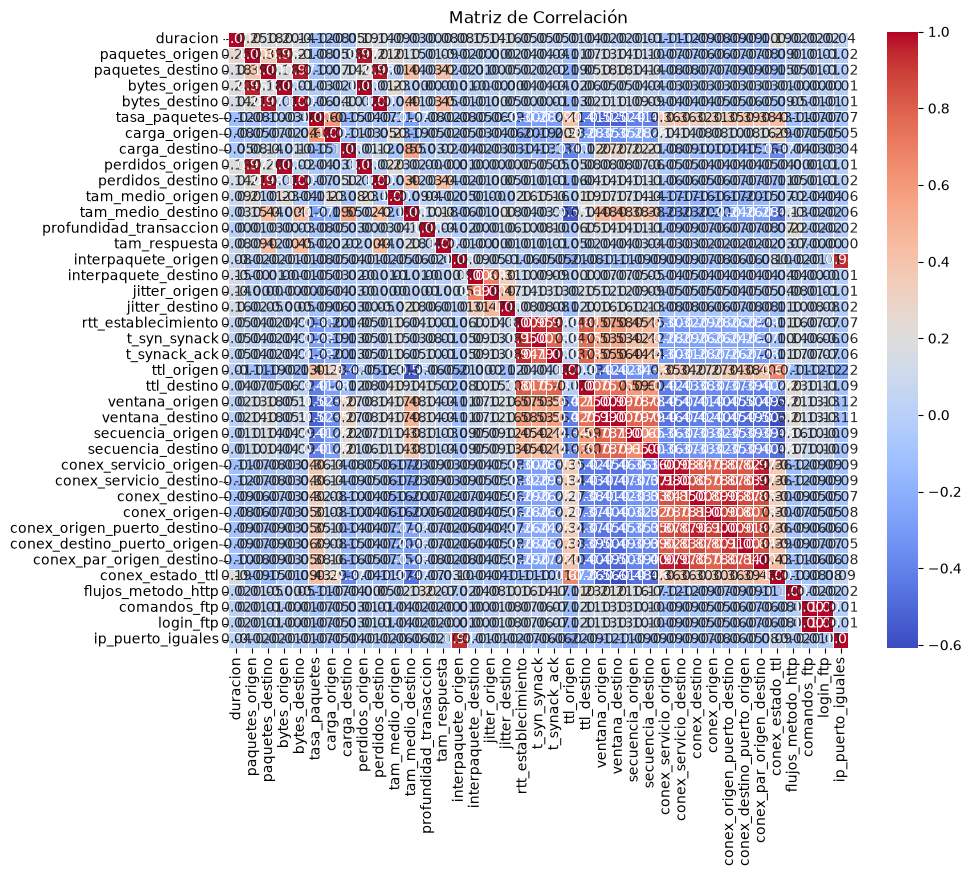

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Cargar tu dataset (ejemplo)

# 2. Calcular la matriz de correlación (solo para variables numéricas)
matriz_corr = cuantitativas.corr(method='pearson')

# 3. Visualizar con un mapa de calor (Heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlación")
plt.show()


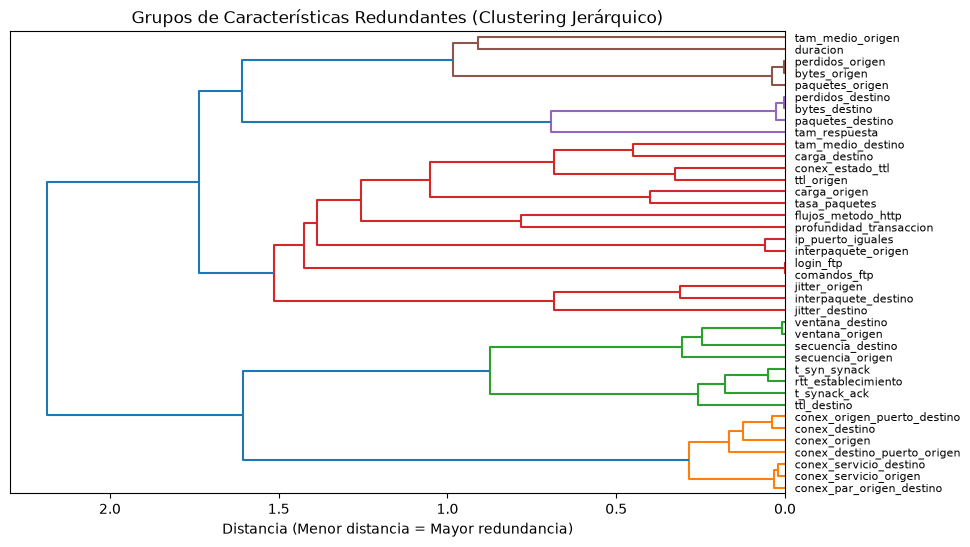

In [13]:
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

# Convertir la matriz de correlación en una matriz de distancias
# (A mayor correlación, menor distancia)
distancia = 1 - abs(matriz_corr)
matriz_condensada = squareform(distancia, checks=False)

# Realizar el agrupamiento jerárquico
enlace = hierarchy.ward(matriz_condensada)

# Dibujar el dendrograma
plt.figure(figsize=(10, 6))
hierarchy.dendrogram(enlace, labels=matriz_corr.columns, orientation='left')
plt.title("Grupos de Características Redundantes (Clustering Jerárquico)")
plt.xlabel("Distancia (Menor distancia = Mayor redundancia)")
plt.show()


In [12]:
# Definir un umbral de redundancia (ej. 85%)
umbral = 0.85

# Encontrar pares de características correlacionadas
columnas_a_eliminar = set()
for i in range(len(matriz_corr.columns)):
    for j in range(i):
        if abs(matriz_corr.iloc[i, j]) > umbral:
            colname = matriz_corr.columns[i]
            columnas_a_eliminar.add(colname)

print(f"Características redundantes a eliminar: {list(columnas_a_eliminar)}")
# df_filtrado = df.drop(columns=columnas_a_eliminar)


Características redundantes a eliminar: ['t_synack_ack', 'ventana_destino', 'conex_origen_puerto_destino', 'bytes_origen', 'conex_servicio_destino', 'ip_puerto_iguales', 'bytes_destino', 'conex_par_origen_destino', 'login_ftp', 't_syn_synack', 'conex_destino_puerto_origen', 'conex_origen', 'perdidos_destino', 'perdidos_origen', 'conex_destino']


## Calculamos la asociación entre las variables categóricas y la etiqueta:

### Usamos el coeficiente de incertidumbre de Theil, que nos da una medida asimétrica de la información que proporcionan las variables predictoras categóricas. Mide el porcentaje de incertidumbre de la etiqueta que se reduce al conocer la variable predictora.

In [14]:
# Crea un nuevo DataFrame que contiene únicamente las columnas cualitativas
df_categorico = df.select_dtypes(include=['object', 'category'])

# Mostrar las primeras filas del nuevo DataFrame
print(df_categorico.head())


  protocolo servicio estado_conexion        etiqueta
0       udp      dns             INT  Criptoanalisis
1       tcp        -             FIN         Fuzzing
2       tcp        -             FIN  Reconocimiento
3       udp      dns             INT  Criptoanalisis
4       arp        -             CON          Normal


C:\Users\silve\AppData\Local\Temp\ipykernel_18564\1160449964.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_categorico = df.select_dtypes(include=['object', 'category'])


In [17]:

from dython.nominal import theils_u


u_theil = theils_u(df['protocolo'], df['etiqueta'])
print(f"U de Theil (Reducción de incertidumbre) protocolo: {u_theil:.4f}")

u_theil = theils_u(df['servicio'], df['etiqueta'])
print(f"U de Theil (Reducción de incertidumbre) servicio: {u_theil:.4f}")

u_theil = theils_u(df['estado_conexion'], df['etiqueta'])
print(f"U de Theil (Reducción de incertidumbre) estado_conexion: {u_theil:.4f}")




U de Theil (Reducción de incertidumbre) protocolo: 0.2913
U de Theil (Reducción de incertidumbre) servicio: 0.3805
U de Theil (Reducción de incertidumbre) estado_conexion: 0.3282


In [19]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import TruncatedSVD
import pandas as pd


encoder = OneHotEncoder(sparse_output=True, handle_unknown='ignore')
matriz_dispersa = encoder.fit_transform(df_categorico)

print(f"Forma de la matriz dispersa: {matriz_dispersa.shape}") 

svd = TruncatedSVD(n_components=2, random_state=42)
matriz_reducida = svd.fit_transform(matriz_dispersa)


print(f"Varianza explicada por los componentes: {svd.explained_variance_ratio_.sum():.4f}")


Forma de la matriz dispersa: (157808, 165)
Varianza explicada por los componentes: 0.4210


### Viendo el resultado anterior, no compensa realizar PCA ya que al reducir el número de variables, estamos explicando un porcentaje demasiado bajo de la varianza (42% respecto al +90% deseado).

### Tratamos los valores poco frecuentes de la columna protocolo:



In [20]:
# 1. Definir el umbral (2% de los datos)
umbral_porcentaje = 0.02

# 2. Calcular la frecuencia relativa de cada categoría
frecuencias_relativas = df_categorico['protocolo'].value_counts(normalize=True)

# 3. Identificar las categorías que no alcanzan el umbral
categorias_raras = frecuencias_relativas[frecuencias_relativas < umbral_porcentaje].index

# 4. Reemplazar esas categorías por 'Otros'
df_categorico['protocolo'] = df_categorico['protocolo'].replace(categorias_raras, 'Otros')


### Volvemos a aplicar One-Hot enconding y Truncated SVD sobre la matriz dispersa: No hacer esto distorsiona los ejes porque se crearán columnas de la matriz dispersa en las cuales la mayoría de los elementos serán cero, porque hay pocos elementos de dicha categoría. Agrupar los valores poco frecuentes en una variable reduce esa distorsión de los ejes. 

In [21]:
encoder = OneHotEncoder(sparse_output=True, handle_unknown='ignore')
matriz_dispersa = encoder.fit_transform(df_categorico)

print(f"Forma de la matriz dispersa: {matriz_dispersa.shape}") 

svd = TruncatedSVD(n_components=2, random_state=42)
matriz_reducida = svd.fit_transform(matriz_dispersa)


print(f"Varianza explicada por los componentes: {svd.explained_variance_ratio_.sum():.4f}")

Forma de la matriz dispersa: (157808, 36)
Varianza explicada por los componentes: 0.4221


## Análisis de componentes principales sobre las variables cuantitativas:

In [ ]:
pca = PCA()
df_pca = pca.fit_transform(df_scaled)

varianza = pca.explained_variance_ratio_ * 100

varianza_acumulada = np.cumsum(varianza)

resultados = pd.DataFrame({
    "Componente": [
        f"PC{i+1}" for i in range(len(varianza))
    ],
    "Varianza explicada (%)": varianza,
    "Varianza acumulada (%)": varianza_acumulada
})

display(resultados.round(2))

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,25.44,25.44
1,PC2,9.79,35.24
2,PC3,9.13,44.37
3,PC4,7.68,52.05
4,PC5,6.15,58.20
5,PC6,5.43,63.63
6,PC7,5.09,68.72
7,PC8,4.76,73.48
8,PC9,3.04,76.52
9,PC10,2.96,79.48


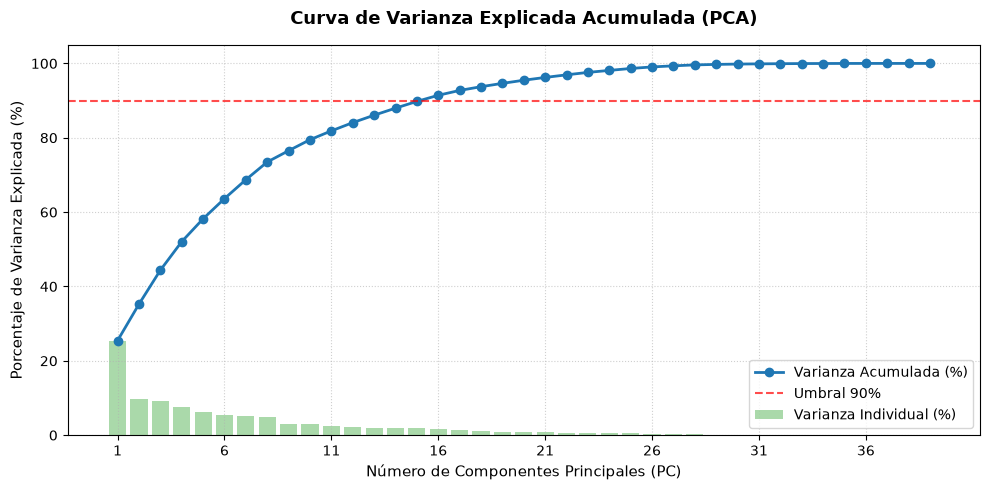

In [36]:
import matplotlib.pyplot as plt

# 1. Configurar el tamaño del gráfico
plt.figure(figsize=(10, 5))

# 2. Dibujar la línea de varianza acumulada (Línea principal)
plt.plot(
    range(1, len(varianza_acumulada) + 1), 
    varianza_acumulada, 
    marker='o', 
    linestyle='-', 
    color='#1f77b4', 
    linewidth=2, 
    label='Varianza Acumulada (%)'
)

# 3. Dibujar las barras de varianza individual (Opcional, ayuda a ver el aporte de cada PC)
plt.bar(
    range(1, len(varianza) + 1), 
    varianza, 
    alpha=0.4, 
    color='#2ca02c', 
    label='Varianza Individual (%)'
)

# 4. Añadir una línea horizontal de referencia al 90%
plt.axhline(y=90, color='r', linestyle='--', alpha=0.7, label='Umbral 90%')

# 5. Personalizar etiquetas y diseño
plt.title('Curva de Varianza Explicada Acumulada (PCA)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Número de Componentes Principales (PC)', fontsize=11)
plt.ylabel('Porcentaje de Varianza Explicada (%)', fontsize=11)

# Forzar que el eje X muestre los números de componentes de 1 en 1 si no son demasiados
if len(varianza) <= 20:
    plt.xticks(range(1, len(varianza) + 1))
else:
    # Si son muchas (como tus 43), mostramos de 5 en 5 para que no se amontonen los números
    plt.xticks(range(1, len(varianza) + 1, 5))

plt.ylim(0, 105) # El límite superior un poco más de 100 para que se vea el final de la curva
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)

# 6. Mostrar el gráfico
plt.tight_layout()
plt.show()


## Calculamos en que porcentaje las variables definen a PC1 y PC2:

In [44]:

cargas_df = pd.DataFrame(
    pca.components_[0:2].T, 
    columns=['PC1', 'PC2'], 
    index=cuantitativas.columns # El nombre de tus 43 variables originales
)

# 2. Añadir columnas de valor absoluto para poder ordenar por relevancia real (sin importar el signo)
cargas_df['Impacto_Abs_PC1'] = cargas_df['PC1'].abs()
cargas_df['Impacto_Abs_PC2'] = cargas_df['PC2'].abs()

# 3. Presentar las variables ordenadas por su peso en PC1
display(cargas_df.sort_values(by='Impacto_Abs_PC1', ascending=False)[['PC1']].round(3).head(10))
display(cargas_df.sort_values(by='Impacto_Abs_PC2', ascending=False)[['PC2']].round(3).head(10))




,PC1
ventana_destino,0.268
ventana_origen,0.265
conex_par_origen_destino,-0.263
conex_servicio_destino,-0.259
conex_servicio_origen,-0.256
conex_destino_puerto_origen,-0.254
conex_origen_puerto_destino,-0.253
conex_destino,-0.245
conex_origen,-0.234
ttl_destino,0.227


,PC2
paquetes_destino,0.443
perdidos_destino,0.414
bytes_destino,0.412
paquetes_origen,0.283
tam_medio_destino,0.266
tam_respuesta,0.225
perdidos_origen,0.198
bytes_origen,0.192
carga_destino,0.158
ttl_origen,-0.139


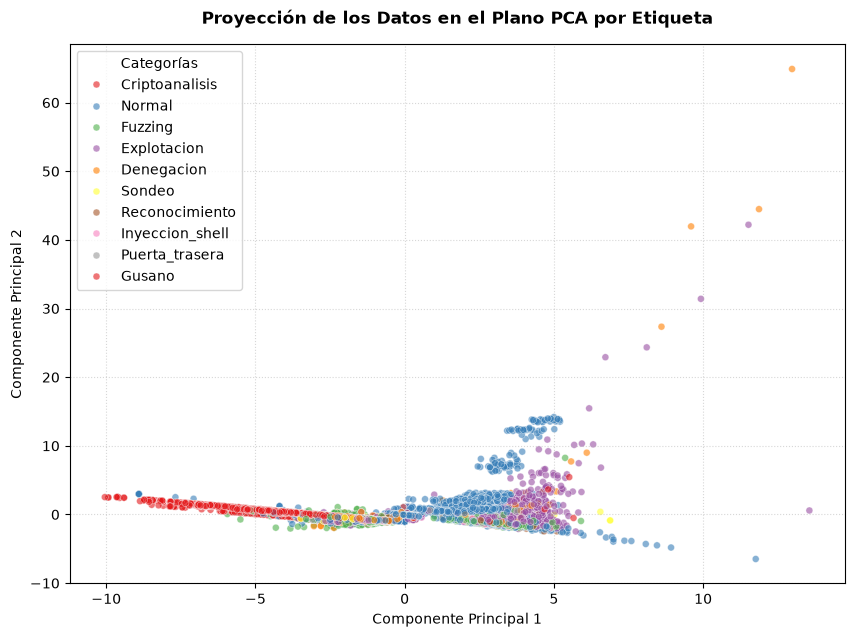

In [47]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Crear un DataFrame con las coordenadas de las componentes y la etiqueta
# df_pca contiene las filas transformadas: pca.fit_transform(df_scaled)
df_plano = pd.DataFrame({
    'PC1': df_pca[:, 0],
    'PC2': df_pca[:, 1],
    'Etiqueta': df['etiqueta'] # Ajusta al nombre real de tu etiqueta
})

# 2. Si el dataset es enorme, tomamos una muestra de 15,000 filas para agilizar el gráfico
if len(df_plano) > 15000:
    df_plano = df_plano.sample(n=15000, random_state=42)

# 3. Graficar con Seaborn
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_plano, 
    x='PC1', 
    y='PC2', 
    hue='Etiqueta', # Muestra los colores según la categoría
    palette='Set1', # Paleta de colores definidos para clases
    alpha=0.6, 
    s=25
)

plt.title('Proyección de los Datos en el Plano PCA por Etiqueta', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(title='Categorías', loc='best')
plt.show()


### Aplicamos ISOMAP:

In [59]:
df_muestra = df.sample(n=2000, random_state=42)
muestra_X = df_muestra.select_dtypes(include="number")
scaler = StandardScaler()
X = scaler.fit_transform(muestra_X)
y = df_muestra['etiqueta']


from matplotlib import offsetbox

from sklearn.manifold import Isomap

isomap = Isomap(n_neighbors=20, n_components=2)
X_projected = isomap.fit_transform(X)






C:\Users\silve\AppData\Roaming\Python\Python314\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\silve\AppData\Roaming\Python\Python314\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


([], [])

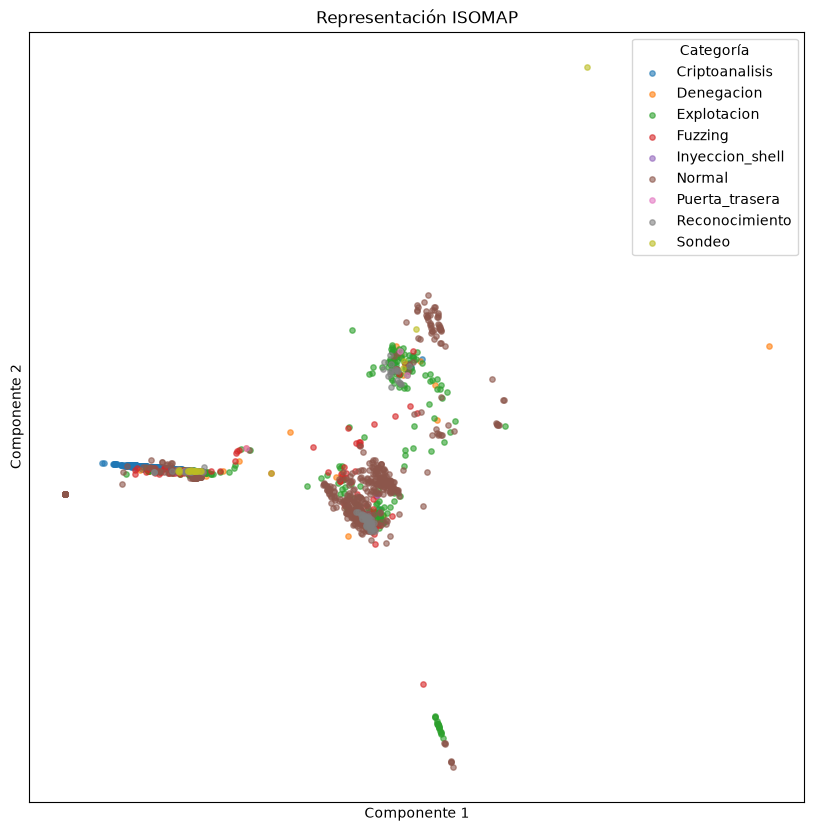

In [61]:
x_min, x_max = np.min(X_projected, 0), np.max(X_projected, 0)

rango = x_max - x_min
rango[rango == 0] = 1

X_projected = (X_projected - x_min) / rango

# Representación gráfica
plt.figure(figsize=(10, 10))

for categoria in np.unique(y):
    mascara = np.asarray(y) == categoria

    plt.scatter(
        X_projected[mascara, 0],
        X_projected[mascara, 1],
        label=str(categoria),
        alpha=0.6,
        s=15
    )

# Configuración del gráfico
plt.title("Representación ISOMAP")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend(title="Categoría")

plt.xticks([])
plt.yticks([])


## Aplicamos t-SNE:

In [62]:
from sklearn.manifold import TSNE

perplexity = 34  #@param {type: "slider", min: 5, max: 50, step: 1}


tsne = TSNE(n_components=2, perplexity=perplexity)
X_projected = tsne.fit_transform(X)



([], [])

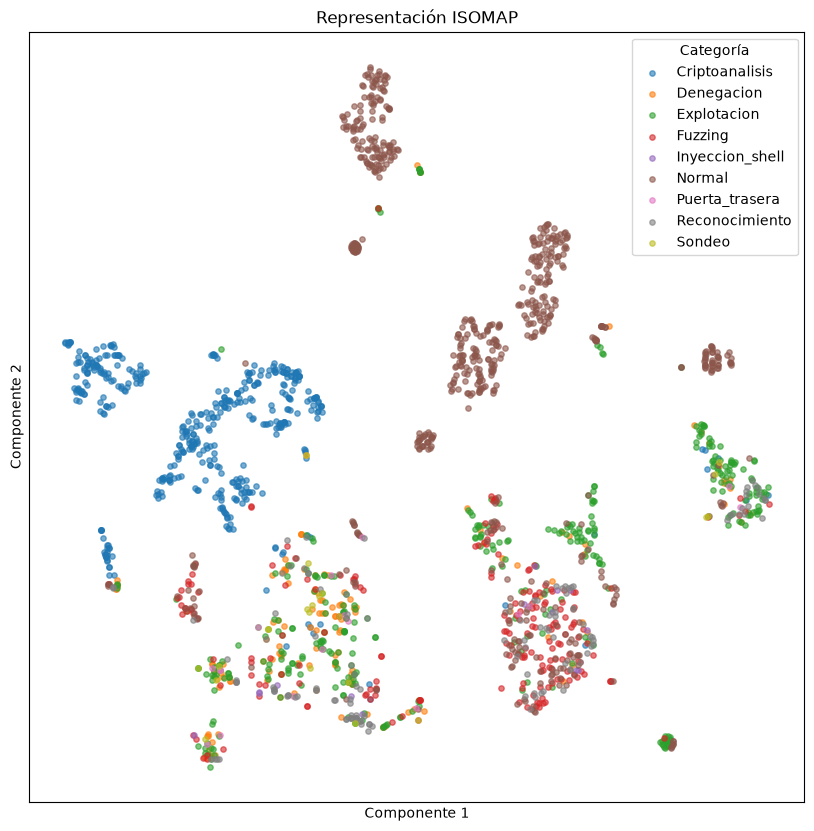

In [63]:
x_min, x_max = np.min(X_projected, 0), np.max(X_projected, 0)

rango = x_max - x_min
rango[rango == 0] = 1

X_projected = (X_projected - x_min) / rango

# Representación gráfica
plt.figure(figsize=(10, 10))

for categoria in np.unique(y):
    mascara = np.asarray(y) == categoria

    plt.scatter(
        X_projected[mascara, 0],
        X_projected[mascara, 1],
        label=str(categoria),
        alpha=0.6,
        s=15
    )

# Configuración del gráfico
plt.title("Representación ISOMAP")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend(title="Categoría")

plt.xticks([])
plt.yticks([])

### Después de aplicar ISOMAP y t-SNE sobre una muestra de 2000 trazas del dataset original, comprobamos que t-SNE consigue separar mejor las distintas clases. ISOMAP conserva la geometría global de los datos (manifold), pero hace posible su visualización en 2-3 dimensiones, sin perder su esencia. t-SNE intenta mantener próximos en el espacio reducido aquellas trazas que eran próximas en el espacio original. Busca las representaciones en menos dimensiones que conserven las probabilidades de vecindad entre los puntos del espacio original, y luego encuentra la menor diferencia KL para encontrar la distribución reducida óptima.

### Después de observar el gráfico de ISOMAP, la mayoría de los valores posibles de etiqueta se encuentran solapados en todas las zonas del gráfico. Por otro lado, se observan dos líneas rectas de trazas, las cuales no podemos confirmar que se trate de PC1 y PC2.

### Después de observar el gráfico de t-SNE, los valores de la etiqueta que se solapan son: reconocimiento, fuzzing y normal. En las demás regiones del gráfico encontramos claramente diferenciadas a normal, criptoanálisis y en pequeñas zonas a explotación. En el resto del gráfico, casi todas las clases se encuentran mezcladas. Además, hay clases como puerta_trasera, inyeccion_web y sondeo que se encuentran muy poco representadas.